<a href="https://colab.research.google.com/github/Shreenisha-S30/mini-projects-on-ML/blob/main/ML_day1_salary_prediction_LR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import seaborn as sns

In [ ]:
!pip install scikit-learn

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
df = pd.read_csv('/content/Salary Data.csv')
df.head(9)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0
6,42.0,Female,Master's,Product Manager,12.0,120000.0
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [ ]:
df.isnull().sum()

,0
Age,2
Gender,2
Education Level,2
Job Title,2
Years of Experience,2
Salary,2


In [ ]:
df.dropna(inplace = True)
df.isnull().sum()

,0
Age,0
Gender,0
Education Level,0
Job Title,0
Years of Experience,0
Salary,0


In [ ]:
df.duplicated().sum()

np.int64(49)

In [ ]:
df.drop_duplicates(inplace = True)
df.duplicated().sum()

np.int64(0)

<Axes: ylabel='Age'>

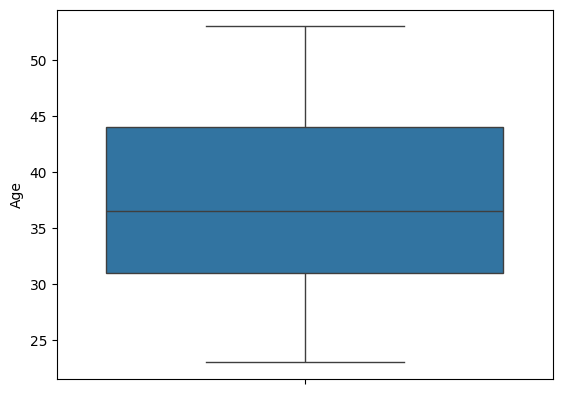

In [ ]:
sns.boxplot(df['Age'])

<Axes: ylabel='Education Level'>

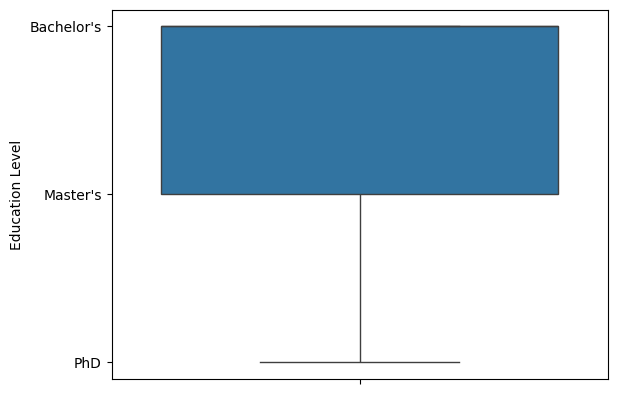

In [ ]:
sns.boxplot(df["Education Level"])

In [ ]:
GE = LabelEncoder()
df["Gender_encoder"] = GE.fit_transform(df["Gender"])
df.head(9)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Gender_encoder
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,1
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,0
4,52.0,Male,Master's,Director,20.0,200000.0,1
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0,1
6,42.0,Female,Master's,Product Manager,12.0,120000.0,0
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0,1
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0,0


In [ ]:
ELE = LabelEncoder()
df["Education_encoder"] = ELE.fit_transform(df["Education Level"])
df.head(19)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Gender_encoder,Education_encoder
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1,0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,0,1
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,1,2
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,0,0
4,52.0,Male,Master's,Director,20.0,200000.0,1,1
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0,1,0
6,42.0,Female,Master's,Product Manager,12.0,120000.0,0,1
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0,1,0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0,0,0
9,38.0,Male,PhD,Senior Scientist,10.0,110000.0,1,2


Separate Dependent and Idependent

In [ ]:
X = df[['Age', 'Years of Experience', 'Gender_encoder', 'Education_encoder']]
Y = df['Salary']
print("Feature shape: ", X.shape, "Target shape:", Y.shape)

Feature shape:  (324, 4) Target shape: (324,)


split train test

In [ ]:
X_train,X_test,Y_train,Y_test = train_test_split(
    X,Y, test_size = 0.20, random_state = 42)

In [ ]:
print("Records for Training: ", len(X_train))
print("Records for Testing: ", len(X_test))

Records for Training:  259
Records for Testing:  65


In [ ]:
num_cols = ["Age", "Years of Experience"]
my_scaler = StandardScaler()
X_train[num_cols] = my_scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = my_scaler.transform(X_test[num_cols])
print(X_train)

          Age  Years of Experience  Gender_encoder  Education_encoder
73  -1.324980            -1.226813               1                  0
182  0.877474             0.714752               0                  2
17   0.189207             0.266698               1                  2
24   0.464514             0.416049               1                  1
146  0.602167             0.864103               0                  2
..        ...                  ...             ...                ...
189 -1.324980            -1.301488               1                  0
71   0.189207             0.117347               0                  0
106 -1.049673            -1.077461               0                  0
284 -0.361406            -0.181355               1                  0
102  1.565740             1.312156               0                  1

[259 rows x 4 columns]


In [ ]:
#training model
salary_model = LinearRegression()
salary_model.fit(X_train,Y_train)

LinearRegression()

In [ ]:
#test
y_predict = salary_model.predict(X_test)
result = pd.DataFrame(
    {
        "Actual" : Y_test,
        "Prediction_by_model" : y_predict
    }
)
result.head(10)

,Actual,Prediction_by_model
132,100000.0,116136.607289
108,100000.0,124667.619930
137,50000.0,49205.367039
9,110000.0,127707.611369
181,105000.0,106510.651731
126,95000.0,99010.342045
221,45000.0,49269.607001
198,55000.0,57800.619642
279,180000.0,167515.403021
144,40000.0,43205.440089


In [ ]:
#predict
age = int(input("Enter age:"))
yoe = int(input("Enter years of experience:"))
gen = input("Enter gender:Male,Female:")
el = input("Enter education: bachelor's, Master's, PhD: ")

Enter age:30
Enter years of experience:3
Enter gender:Male,Female:Female
Enter education: bachelor's, Master's, PhD: PhD


In [ ]:
gen = GE.transform([gen])[0]
el = ELE.transform([el])[0]

In [ ]:
age, yop = my_scaler.transform([[age,yoe]])[0]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
result = salary_model.predict([[age,yoe,gen,el]])
print("predicted salary is:",result)

predicted salary is: [154410.4894321]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
#evaluate using test data
import numpy as np
mae = mean_absolute_error(Y_test, y_predict)
mse = mean_squared_error(Y_test,y_predict)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, y_predict)
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2 SCORE:",r2) #that many vairations it can catch and how many patterns it can recognize

MAE: 10547.125753940905
MSE: 205342321.19904488
RMSE: 14329.770451721999
R2 SCORE: 0.8913410224920044


Since r2 score is approx 0.9, it can recognize 90% of patterns and variations in salary based on age, gender, years of exprience and education level.